# Clase 2 — Semántica vectorial

En la clase representamos cinco sinopsis de películas de tres formas: conteos de palabras (bolsa de palabras), pesos TF-IDF y coordenadas LSA. Este tutorial recorre las tres, en dos pasos:

1. **A mano**, con las cinco sinopsis: la matriz documento-término, el producto punto, el coseno y TF-IDF, hasta llegar a los números de las diapositivas.
2. **Con scikit-learn**, sobre las sinopsis de 20.559 películas de la Wikipedia en español: `CountVectorizer`, `TfidfVectorizer` y `TruncatedSVD` (LSA).

Al final damos vuelta la matriz: las mismas columnas sirven para comparar **palabras**, que es el punto de partida de la clase 3.

**Objetivos**

- Construir una matriz documento-término y comparar documentos con la similitud coseno.
- Entender qué cambia TF-IDF y qué agrega LSA.
- Usar los vectorizadores de scikit-learn: ajustar sobre un corpus (`fit`) y representar textos nuevos (`transform`).

## 0. Preparación

En Colab ya están instalados pandas, scikit-learn, matplotlib, wordcloud y spaCy. La celda siguiente instala los que falten en una instalación local.

In [1]:
%%capture
%pip install -q wordcloud spacy

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from spacy.lang.es.stop_words import STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", None)

STOPWORDS = sorted(STOP_WORDS)  # lista de spaCy, como en la clase 1

# Parte 1 — A mano, con cinco sinopsis

## 1. Las cinco sinopsis de la clase

Órbita es la referencia y las otras cuatro se comparan con ella. ¿Cuál se parece más?

In [3]:
sinopsis = pd.Series({
    "Órbita": (
        "Una astronauta viaja al espacio durante un año para estudiar la "
        "química de una estrella cercana. A esa distancia pierde el "
        "contacto con la base, y la atracción de la estrella empieza a "
        "sacar su cápsula de órbita. Sin señal, debe buscar la forma de "
        "volver."
    ),
    "Deriva": (
        "Un astronauta analiza la química de un cometa desde una cápsula "
        "en órbita. Cuando una tormenta daña la antena, la señal se corta "
        "y el módulo queda a la deriva en el espacio."
    ),
    "Masa madre": (
        "Dos hermanas heredan la panadería de su madre. Entre deudas y "
        "recetas antiguas, intentan salvarla y descubren secretos que "
        "cambian lo que creían saber de ella."
    ),
    "La casa del sur": (
        "Un año después de la muerte de su padre, Marta viaja al pueblo "
        "donde creció para vender la casa. Pierde el contacto con la "
        "ciudad y empieza a dudar. Cuando encuentra una carta de su madre, "
        "debe buscar la forma de volver."
    ),
    "Destino Kepler": (
        "Tras décadas a bordo de una nave que viaja rumbo a otro planeta, "
        "la tripulación despierta del sueño criogénico y descubre que el "
        "piloto automático cambió el destino. Cada año de desvío cuenta, "
        "y empieza una carrera para buscar la forma de volver a la ruta."
    ),
})
titulos = list(sinopsis.index)
sinopsis

Órbita              Una astronauta viaja al espacio durante un año para estudiar la química de una estrella cercana. A esa distancia pierde el contacto con la base, y la atracción de la estrella empieza a sacar su cápsula de órbita. Sin señal, debe buscar la forma de volver.
Deriva                                                                                                Un astronauta analiza la química de un cometa desde una cápsula en órbita. Cuando una tormenta daña la antena, la señal se corta y el módulo queda a la deriva en el espacio.
Masa madre                                                                                                          Dos hermanas heredan la panadería de su madre. Entre deudas y recetas antiguas, intentan salvarla y descubren secretos que cambian lo que creían saber de ella.
La casa del sur                                        Un año después de la muerte de su padre, Marta viaja al pueblo donde creció para vender la casa. Pierde el contacto c

## 2. Bolsa de palabras

Tokenizamos como en la clase 1: una expresión regular que separa palabras de dos o más caracteres, en minúsculas. Después quitamos las stopwords con la lista de spaCy.

In [4]:
def tokenizar(texto: str) -> list[str]:
    """Devuelve las palabras de dos o más caracteres, en minúsculas."""
    return re.findall(r"\w\w+", texto.lower())


documentos = {titulo: [p for p in tokenizar(texto) if p not in STOP_WORDS]
              for titulo, texto in sinopsis.items()}
documentos["Órbita"]

['astronauta',
 'viaja',
 'espacio',
 'año',
 'estudiar',
 'química',
 'estrella',
 'cercana',
 'distancia',
 'pierde',
 'contacto',
 'base',
 'atracción',
 'estrella',
 'empieza',
 'sacar',
 'cápsula',
 'órbita',
 'señal',
 'buscar',
 'forma',
 'volver']

El **vocabulario** son todas las palabras distintas, en orden. La **matriz documento-término** tiene una fila por sinopsis y una columna por palabra; cada celda cuenta cuántas veces aparece la palabra en la sinopsis.

In [5]:
vocabulario = sorted({p for tokens in documentos.values() for p in tokens})
X = pd.DataFrame([[Counter(tokens)[p] for p in vocabulario] for tokens in documentos.values()],
                 index=titulos, columns=vocabulario)
print(X.shape)
X.loc[:, X.loc["Órbita"] > 0]

(5, 70)


,astronauta,atracción,año,base,buscar,cercana,contacto,cápsula,distancia,empieza,...,estrella,estudiar,forma,pierde,química,sacar,señal,viaja,volver,órbita
Órbita,1,1,1,1,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
Deriva,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,1,0,0,1
Masa madre,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
La casa del sur,0,0,1,0,1,0,1,0,0,1,...,0,0,1,1,0,0,0,1,1,0
Destino Kepler,0,0,1,0,1,0,0,0,0,1,...,0,0,1,0,0,0,0,1,1,0


In [6]:
#ceros por fila
ceros_por_fila = (X == 0).sum(axis=1)
ceros_por_fila

Órbita             49
Deriva             55
Masa madre         57
La casa del sur    51
Destino Kepler     47
dtype: int64

Son 5 sinopsis × 70 palabras; arriba se muestran solo las columnas de las palabras de Órbita. Cada fila es un vector de 70 coordenadas, y la mayoría vale cero: la representación es **dispersa**. La **bolsa de palabras** conserva los conteos y descarta el orden.


Con miles de documentos y de palabras, la matriz queda casi toda en blanco. Las columnas resaltadas, *cuerda* y *cordel*, vuelven a aparecer en la sección de LSA.

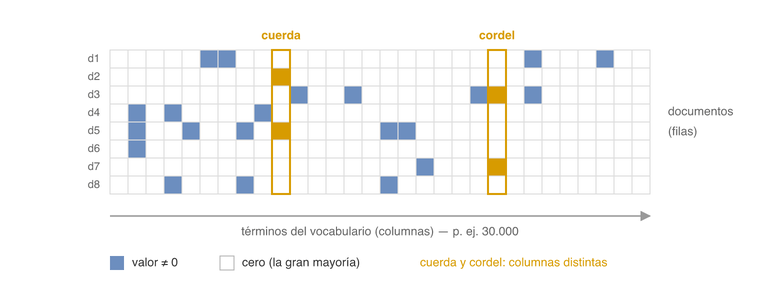

### 2.1 Producto punto

Para comparar dos filas multiplicamos coordenada por coordenada y sumamos. Una palabra que falta en alguna de las dos sinopsis aporta cero.

In [7]:
X @ X.loc["Órbita"]

Órbita             24
Deriva              6
Masa madre          0
La casa del sur     8
Destino Kepler      6
dtype: int64

Deriva comparte seis palabras con Órbita; La casa del sur, ocho; Masa madre, ninguna. Pero el producto punto crece con el largo del texto: si repetimos la sinopsis de Deriva dos veces, sin agregar información, el resultado se duplica.

In [8]:
deriva_doble = 2 * X.loc["Deriva"]
deriva_doble @ X.loc["Órbita"]

np.int64(12)

### 2.2 Similitud coseno

El coseno divide el producto punto por los largos (normas) de los dos vectores, y así compara solo su dirección:

$$\cos(\mathbf a, \mathbf b) = \frac{\mathbf a \cdot \mathbf b}{\|\mathbf a\|\,\|\mathbf b\|}$$

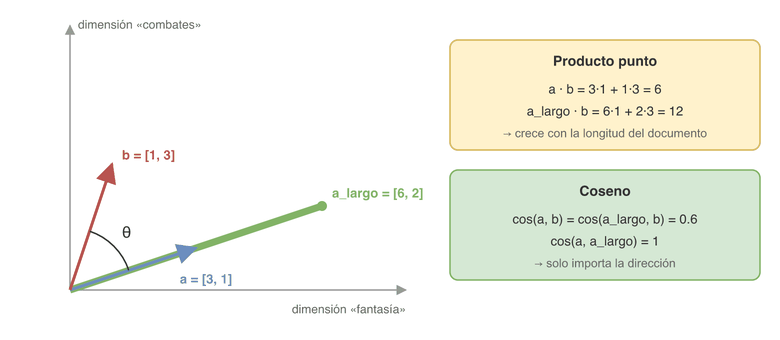

Con conteos, el resultado va de 0 (ninguna palabra en común) a 1 (misma dirección).

In [9]:
def coseno(a, b):
    return (a @ b) / (np.sqrt(a @ a) * np.sqrt(b @ b))


print("Deriva:      ", round(coseno(X.loc["Deriva"], X.loc["Órbita"]), 2))
print("Deriva doble:", round(coseno(deriva_doble, X.loc["Órbita"]), 2))

sim_mano_bow = X.apply(coseno, axis=1, b=X.loc["Órbita"])
sim_mano_bow

Deriva:       0.32
Deriva doble: 0.32


Órbita             1.00
Deriva             0.32
Masa madre         0.00
La casa del sur    0.37
Destino Kepler     0.26
dtype: float64

Son los números de la diapositiva: Deriva 0,32, Masa madre 0, La casa del sur 0,37 y Destino Kepler 0,26. Con conteos gana La casa del sur, un drama familiar, porque comparte más palabras con Órbita: *año*, *viaja*, *pierde*, *contacto*, *empieza*, *buscar*, *forma*, *volver*.

## 3. TF-IDF

Esas ocho palabras aparecen en cualquier sinopsis. *Astronauta* o *cápsula*, en cambio, distinguen a una película de las demás. TF-IDF le da a cada palabra un peso según en cuántos documentos aparece:

$$\mathrm{idf}(t) = \log_{10}\frac{N}{\mathrm{df}(t)},\qquad \text{tf-idf}(t, d) = \mathrm{tf}(t, d)\cdot\mathrm{idf}(t)$$

donde $N = 5$ es el número de sinopsis y $\mathrm{df}(t)$ el número de sinopsis que contienen la palabra $t$.

In [10]:
N = len(X)
df = (X > 0).sum(axis=0)
idf = np.log10(N / df)
pd.DataFrame({"df": df, "idf": idf}).loc[["astronauta", "cápsula", "año", "forma", "volver"]]

,df,idf
astronauta,2,0.40
cápsula,2,0.40
año,3,0.22
forma,3,0.22
volver,3,0.22


In [11]:
X_mano_tfidf = X * idf   # cada columna se multiplica por su idf
sim_mano_tfidf = X_mano_tfidf.apply(coseno, axis=1, b=X_mano_tfidf.loc["Órbita"])
pd.DataFrame({"BoW": sim_mano_bow, "TF-IDF": sim_mano_tfidf}).drop("Órbita")

,BoW,TF-IDF
Deriva,0.32,0.16
Masa madre,0.00,0.00
La casa del sur,0.37,0.10
Destino Kepler,0.26,0.04


Ahora gana Deriva (0,16) y La casa del sur baja a 0,10. Los valores de las dos columnas no se comparan entre sí: importa el orden dentro de cada una.

Queda un problema. Destino Kepler también transcurre en el espacio, pero queda en 0,04: dice *nave* donde Órbita dice *cápsula*, y *tripulación* donde dice *astronauta*. En esta matriz cada palabra es un eje independiente, y dos documentos solo se parecen si comparten palabras. Con cinco sinopsis no hay cómo saber que *nave* y *cápsula* se usan en los mismos contextos. Para eso necesitamos un corpus más grande.

# Parte 2 — Con scikit-learn, sobre Wikipedia

## 4. El corpus

Los datos vienen del volcado de la Wikipedia en español de noviembre de 2023 (`wikimedia/wikipedia`, configuración `20231101.es`). El archivo tiene una fila por película, con su título, año, géneros, la sección «Argumento», «Sinopsis» o «Trama» del artículo (columna `argumento`). El texto de Wikipedia se distribuye bajo la licencia CC BY-SA 4.0.

In [12]:
ARCHIVO = "https://raw.githubusercontent.com/dccuchile/CC66Q/main/tutorials/data/peliculas_wikipedia.csv.gz"

peliculas = pd.read_csv(ARCHIVO)
peliculas.shape

(29762, 4)

No todos los artículos tienen una sección de argumento. Nos quedamos con los que la tienen, y esa sección es el documento.

In [13]:
corpus = peliculas.dropna(subset=["argumento"]).reset_index(drop=True)
textos = corpus["argumento"].tolist()
len(textos)

20559

In [14]:
corpus[["titulo", "anio", "generos"]].sample(5, random_state=0)

,titulo,anio,generos
14756,Clara es el precio,1975.0,NaN
18999,Sirena,NaN,NaN
18893,The Kid Brother,1927.0,comedia|romance|drama
8541,Tabou,2010.0,NaN
9602,Sube y baja,1959.0,comedia


In [15]:
print(corpus.loc[0, "titulo"])
print(textos[0][:500])

Blade Runner
En la ciudad de Los Ángeles, en noviembre de 2019, un blade runner excesivamente confiado —Dave Holden— recibe un tiro mientras llevaba a cabo el test Voight-Kampff a Leon Kowalski, un replicante fugitivo en la Tierra. Un antiguo blade runner, Rick Deckard, se encuentra en «The White Dragon Noodle Bar» de Howie Lee, el Maestro del Sushi, cuando es localizado por Gaff. Este le indica que el capitán Harry Bryant, su antiguo jefe, quiere verle. Dubitativo, se encuentra con Bryant, quien le informa 


In [16]:
corpus["argumento"].str.split().str.len().describe().round()

count    20559.0
mean       289.0
std        380.0
min         40.0
25%         73.0
50%        125.0
75%        356.0
max       6474.0
Name: argumento, dtype: float64

### 4.1 Frecuencias de palabras

Contamos las palabras de todo el corpus con el mismo `tokenizar` de la parte 1.

In [17]:
frecuencias = Counter()
for texto in textos:
    frecuencias.update(tokenizar(texto))

len(frecuencias), frecuencias.most_common(10)

(110665,
 [('de', 342044),
  ('la', 219456),
  ('que', 190398),
  ('el', 153033),
  ('en', 144850),
  ('su', 116075),
  ('un', 99970),
  ('se', 98505),
  ('una', 79101),
  ('los', 75596)])

Las palabras más frecuentes son funcionales: *de*, *la*, *que*. Las quitamos con la lista de stopwords de spaCy antes de graficar.

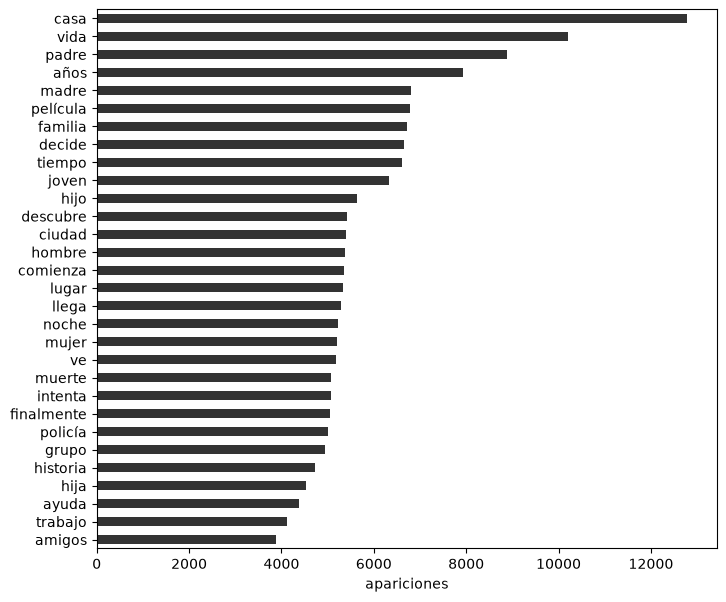

In [18]:
contenido = Counter({palabra: n for palabra, n in frecuencias.items()
                     if palabra not in STOP_WORDS})
top = pd.Series(dict(contenido.most_common(30)))
ax = top[::-1].plot.barh(figsize=(8, 7), color="#333333", xlabel="apariciones")

### 4.2 Nubes de palabras

Una nube por género, con las sinopsis de las películas de ciencia ficción y de las de wéstern.

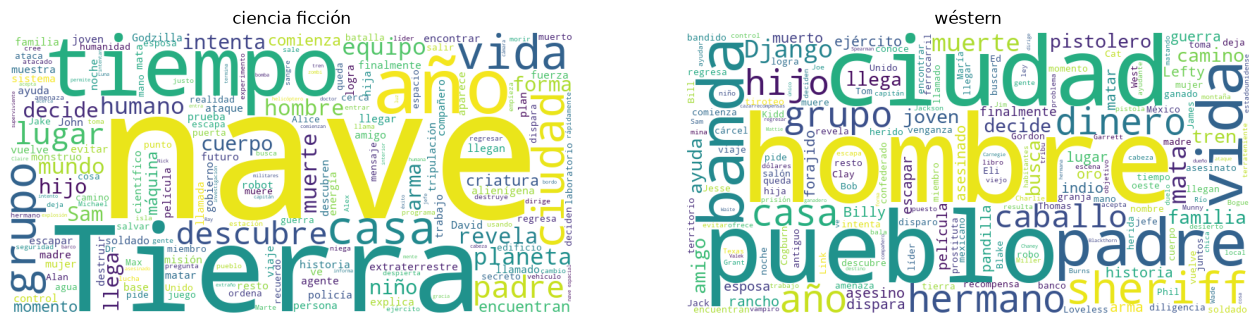

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 4))
for ax, genero in zip(ejes, ["ciencia ficción", "wéstern"]):
    filas = corpus["generos"].str.contains(genero, na=False)
    texto = " ".join(corpus.loc[filas, "argumento"])
    nube = WordCloud(width=800, height=400, background_color="white",
                     stopwords=STOP_WORDS, random_state=0).generate(texto)
    ax.imshow(nube)
    ax.set_title(genero)
    ax.axis("off")

## 5. Bolsa de palabras con CountVectorizer

Un vectorizador de scikit-learn trabaja en dos pasos. `fit` recorre el corpus y arma el vocabulario: una columna por palabra. `transform` recibe textos y devuelve la matriz, con una fila por texto. Los argumentos se fijan al crear el vectorizador. Abajo están los principales, con su valor por defecto salvo `stop_words`.

scikit-learn solo trae una lista de stopwords para inglés. Sin lista, *de*, *la* y *que* entran al vocabulario y dominan el coseno: Masa madre, que no comparte ninguna palabra de contenido con Órbita, queda en 0,30 en vez de 0. Usamos la lista de spaCy, como en la parte 1.

Guía de usuario: [The Bag of Words representation](https://scikit-learn.org/stable/modules/feature_extraction.html#the-bag-of-words-representation).

In [20]:
bow = CountVectorizer(
    strip_accents=None,      # None, "ascii" o "unicode": quita tildes
    lowercase=True,          # pasa a minúsculas antes de tokenizar
    stop_words=STOPWORDS,    # None, "english" o una lista propia
    token_pattern=r"(?u)\b\w\w+\b",  # regex: palabras de 2+ caracteres
    ngram_range=(1, 1),      # (1, 2): unigramas y bigramas
    max_df=1.0,              # ignora palabras en más de esta fracción
    min_df=1,                # ignora palabras en menos de este número
    max_features=None,       # conserva solo las N más frecuentes
    binary=False,            # True: 1 si aparece, 0 si no
)

In [21]:
bow.fit(textos)
len(bow.vocabulary_)

110191

`fit` solo aprendió el vocabulario: 110.191 palabras distintas, después de quitar las stopwords. `token_pattern` es la misma expresión regular de `tokenizar`. Los conteos se calculan al transformar.

In [22]:
X_wiki_bow = bow.transform(textos)
X_wiki_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1937587 stored elements and shape (20559, 110191)>

In [23]:
# % of non zeroes
X_wiki_bow.nnz / np.prod(X_wiki_bow.shape)

np.float64(0.0008552894224647632)

La matriz tiene 20.559 × 110.191 ≈ 2.265 millones de celdas y 1,9 millones distintas de cero: el 0,09 %. scipy guarda solo las celdas distintas de cero (formato CSR), y por eso cabe en memoria.

Las cinco sinopsis se transforman con el mismo vectorizador. Las columnas son las 110.191 del vocabulario de Wikipedia; mostramos solo las de las palabras de Órbita.

In [24]:
X_bow = bow.transform(sinopsis)
X_bow.shape

(5, 110191)

In [25]:
tabla = pd.DataFrame(X_bow.toarray(), index=titulos,
                     columns=bow.get_feature_names_out())
tabla.loc[:, tabla.loc["Órbita"] > 0]

,astronauta,atracción,año,base,buscar,cercana,contacto,cápsula,distancia,empieza,...,estrella,estudiar,forma,pierde,química,sacar,señal,viaja,volver,órbita
Órbita,1,1,1,1,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
Deriva,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,1,0,0,1
Masa madre,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
La casa del sur,0,0,1,0,1,0,1,0,0,1,...,0,0,1,1,0,0,0,1,1,0
Destino Kepler,0,0,1,0,1,0,0,0,0,1,...,0,0,1,0,0,0,0,1,1,0


In [26]:
sim_bow = pd.Series(cosine_similarity(X_bow)[0], index=titulos)
sim_bow

Órbita             1.00
Deriva             0.32
Masa madre         0.00
La casa del sur    0.37
Destino Kepler     0.26
dtype: float64

Deriva 0,32, Masa madre 0, La casa del sur 0,37, Destino Kepler 0,26. Son los mismos números de la parte 1, porque los conteos de una sinopsis no dependen del corpus: La casa del sur queda primera porque comparte ocho palabras con Órbita, y Deriva seis.

## 6. TF-IDF con TfidfVectorizer

`TfidfVectorizer` tiene los mismos argumentos que `CountVectorizer` y cuatro más, que controlan el peso. Abajo dejamos solo `stop_words` y esos cuatro; el resto queda con su valor por defecto, igual que en la bolsa de palabras. Su fórmula es una variante de la que usamos a mano:

$$\mathrm{idf}(t) = \ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1$$

y después normaliza cada fila para que tenga largo 1 (`norm="l2"`), así que el coseno entre dos filas es su producto punto.

Guía de usuario: [Tf–idf term weighting](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).

In [27]:
tfidf = TfidfVectorizer(
    stop_words=STOPWORDS,    # None, "english" o una lista propia
    norm="l2",               # "l2", "l1" o None: normaliza cada fila
    use_idf=True,            # False: solo tf
    smooth_idf=True,         # suma 1 a N y a df (la fórmula de arriba)
    sublinear_tf=False,      # True: 1 + log(tf) en vez de tf
)

`fit` recorre el corpus y guarda, además del vocabulario, el idf de cada palabra (atributo `idf_`). Para ver el df, contamos en la matriz BoW en cuántas sinopsis aparece cada palabra.

In [28]:
tfidf.fit(textos)

palabras = ["astronauta", "cápsula", "nave", "año", "forma", "volver"]
pesos = pd.DataFrame({"df": (X_wiki_bow > 0).sum(axis=0).A1,
                      "idf": tfidf.idf_},
                     index=tfidf.get_feature_names_out())
pesos.loc[palabras]

,df,idf
astronauta,37,7.29
cápsula,79,6.55
nave,414,4.90
año,1299,3.76
forma,2079,3.29
volver,1517,3.61


*Astronauta* aparece en 37 sinopsis y pesa 7,29; *año* aparece en 1.299 y pesa 3,76. En la parte 1, con N = 5, los mismos pesos eran 0,40 y 0,22. El corpus de referencia ahora son las 20.559 sinopsis.

In [29]:
X_tfidf = tfidf.transform(sinopsis)
tabla = pd.DataFrame(X_tfidf.toarray(), index=titulos,
                     columns=tfidf.get_feature_names_out())
tabla.loc[:, tabla.loc["Órbita"] > 0]

,astronauta,atracción,año,base,buscar,cercana,contacto,cápsula,distancia,empieza,...,estrella,estudiar,forma,pierde,química,sacar,señal,viaja,volver,órbita
Órbita,0.3,0.22,0.15,0.19,0.15,0.21,0.18,0.27,0.22,0.15,...,0.36,0.22,0.14,0.17,0.27,0.2,0.22,0.17,0.15,0.27
Deriva,0.3,0.00,0.00,0.00,0.00,0.00,0.00,0.27,0.00,0.00,...,0.00,0.00,0.00,0.00,0.27,0.0,0.22,0.00,0.00,0.27
Masa madre,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
La casa del sur,0.0,0.00,0.20,0.00,0.20,0.00,0.24,0.00,0.00,0.19,...,0.00,0.00,0.18,0.23,0.00,0.0,0.00,0.23,0.20,0.00
Destino Kepler,0.0,0.00,0.15,0.00,0.15,0.00,0.00,0.00,0.00,0.14,...,0.00,0.00,0.13,0.00,0.00,0.0,0.00,0.17,0.14,0.00


In [30]:
sim_tfidf = pd.Series(cosine_similarity(X_tfidf)[0], index=titulos)
sim_tfidf

Órbita             1.00
Deriva             0.40
Masa madre         0.00
La casa del sur    0.27
Destino Kepler     0.14
dtype: float64

Deriva 0,40, Masa madre 0, La casa del sur 0,27, Destino Kepler 0,14. Los números no son los de la parte 1 (0,16, 0, 0,10 y 0,04), porque cambiaron la fórmula y el corpus de referencia. El orden sí: Deriva pasa a La casa del sur, cuyas ocho palabras en común con Órbita aparecen en miles de sinopsis y pesan poco.

## 7. LSA

### 7.1 La idea, en pequeño

Un corpus de juguete: *cuerda* y *cordel* nunca aparecen en el mismo documento, pero sí junto a las mismas palabras (*nudo*, *amarrar*, *barco*). Es el caso de *cápsula* y *nave*.

In [31]:
juguete = ["cuerda nudo amarrar barco", "cuerda nudo muelle", "cuerda amarrar barco muelle",
           "cordel nudo amarrar", "cordel barco muelle", "cordel nudo barco amarrar",
           "receta cocina sartén hervir", "cocina sartén cebolla", "receta hervir cebolla cocina",
           "barco cocina nudo"]
cv = CountVectorizer()
A = cv.fit_transform(juguete).toarray()
palabras_juguete = list(cv.get_feature_names_out())


def coseno_palabras(M, a, b):
    """Coseno entre los vectores de dos palabras (filas de M)."""
    return coseno(M[palabras_juguete.index(a)], M[palabras_juguete.index(b)])


pares = [("cuerda", "cordel"), ("cuerda", "nudo"), ("cuerda", "cocina")]
columnas = A.T   # una fila por palabra, una coordenada por documento
pd.Series({" – ".join(par): coseno_palabras(columnas, *par) for par in pares})

cuerda – cordel    0.00
cuerda – nudo      0.52
cuerda – cocina    0.00
dtype: float64

Como no comparten ningún documento, *cuerda* y *cordel* tienen coseno 0. La descomposición en valores singulares (**SVD**) escribe la matriz como $X = U \Sigma V^\top$. Si conservamos solo los $k$ valores singulares más grandes, cada palabra queda descrita por $k$ números que resumen con qué otras palabras aparece.

In [32]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
k = 2
latentes = Vt[:k].T * s[:k]   # una fila por palabra, k coordenadas
pd.Series({" – ".join(par): coseno_palabras(latentes, *par) for par in pares})

cuerda – cordel    1.00
cuerda – nudo      0.99
cuerda – cocina    0.07
dtype: float64

Con dos dimensiones, *cuerda* y *cordel* quedan casi alineadas y *cuerda* y *cocina* siguen separadas. Esto es el **análisis semántico latente** (LSA; Deerwester et al., 1990). Las dimensiones nuevas resumen patrones de la matriz y no tienen por qué corresponder a temas con nombre.

**¿Qué hizo la SVD con los datos?** Reconstruimos la matriz con solo dos dimensiones, $\hat X = U_k \Sigma_k V_k^\top$, y la comparamos con la original. Las columnas de *cuerda* y *cordel* están recuadradas.

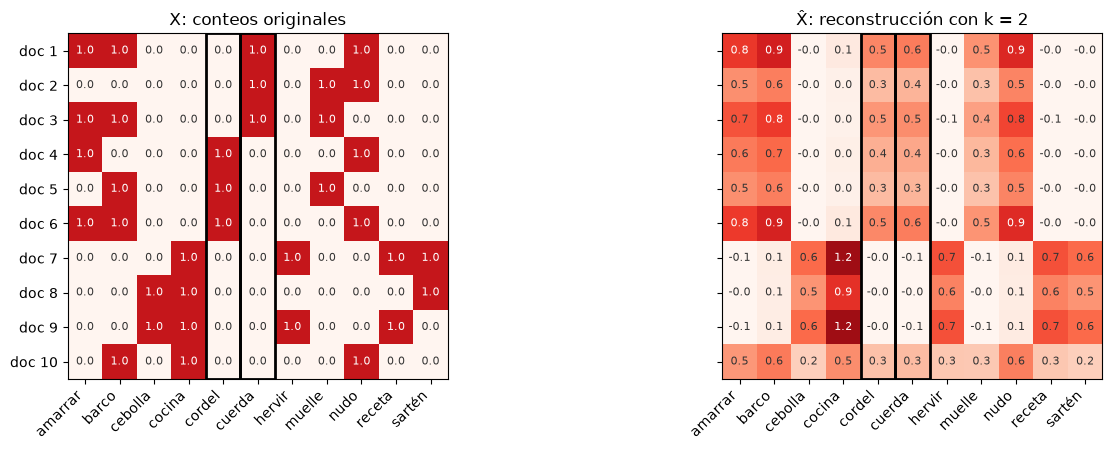

In [33]:
X_k = (U[:, :k] * s[:k]) @ Vt[:k]   # reconstrucción de rango k

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, M, titulo in zip(ejes, [A, X_k], ["X: conteos originales", "X̂: reconstrucción con k = 2"]):
    ax.imshow(M, cmap="Reds", vmin=0, vmax=1.3)
    ax.set_title(titulo)
    ax.set_xticks(range(len(palabras_juguete)), palabras_juguete, rotation=45, ha="right")
    ax.set_yticks(range(len(juguete)), [f"doc {i + 1}" for i in range(len(juguete))])
    for (i, j), valor in np.ndenumerate(M):
        ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=8,
                color="white" if valor > 0.8 else "#333333")
    for palabra in ["cuerda", "cordel"]:   # recuadro en las dos columnas que nos interesan
        j = palabras_juguete.index(palabra)
        ax.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, len(juguete), fill=False, lw=2))
plt.tight_layout()

En $, *cuerda* vale 0 en los documentos 4 a 6, que dicen *cordel*, y *cordel* vale 0 en los documentos 1 a 3. En $\hat X$ las dos columnas son casi iguales: cada palabra recibe un valor positivo (entre 0,3 y 0,6) en los documentos de la otra. Con dos dimensiones no alcanza para guardar cada conteo, así que la SVD conserva el patrón común: seis documentos sobre cuerdas y barcos, tres sobre cocina. El documento 10 (*barco cocina nudo*) no contiene *cuerda* ni *cordel*: las dos valen 0 en $X$. En $\hat X$ ambas reciben 0,3, porque el documento comparte *barco* y *nudo* con los del muelle. Como además dice *cocina*, sus valores quedan repartidos entre los dos temas.

Las mismas dos dimensiones sirven para dibujar las palabras. Cada flecha es el vector de una palabra, y el coseno compara su dirección.

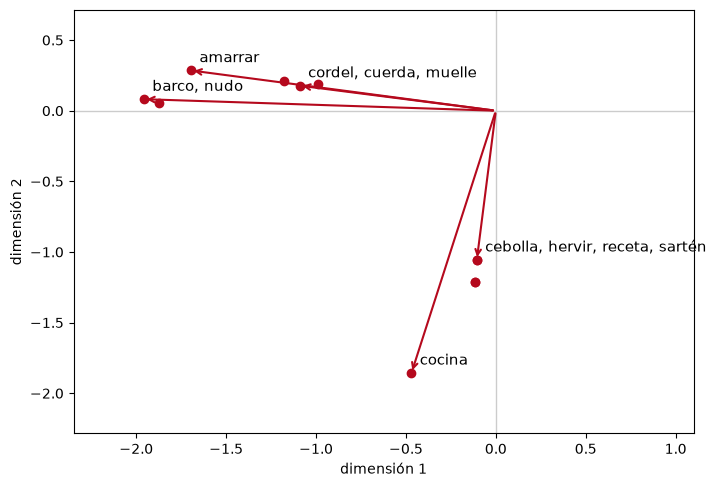

In [34]:
# Las palabras que quedan casi en el mismo punto comparten etiqueta.
grupos = []   # pares (punto, palabras)
for palabra, punto in zip(palabras_juguete, latentes):
    for centro, palabras in grupos:
        if np.linalg.norm(punto - centro) < 0.25:
            palabras.append(palabra)
            break
    else:
        grupos.append((punto, [palabra]))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axhline(0, color="#cccccc", lw=1)
ax.axvline(0, color="#cccccc", lw=1)
for (x, y), palabras in grupos:
    ax.annotate("", (x, y), (0, 0), arrowprops=dict(arrowstyle="->", color="#B5091D", lw=1.5))
    ax.annotate(", ".join(palabras), (x, y), xytext=(6, 6), textcoords="offset points", fontsize=11)
ax.scatter(latentes[:, 0], latentes[:, 1], color="#B5091D")
ax.margins(0.2)
ax.set_xlim(right=1.1)   # espacio para las etiquetas
ax.set_xlabel("dimensión 1")
ax.set_ylabel("dimensión 2");

Las palabras del muelle apuntan casi en la misma dirección, y las de cocina, en otra casi perpendicular. Por eso *cuerda* y *cordel* tienen coseno cercano a 1, y *cuerda* y *cocina*, cercano a 0. Los signos de los ejes son arbitrarios: otra implementación puede devolver el dibujo reflejado sin cambiar ningún coseno.

### 7.2 LSA con TruncatedSVD

`TruncatedSVD` calcula la descomposición $X = U \Sigma V^\top$ de la matriz TF-IDF del corpus y conserva los $k$ valores singulares más grandes. `fit` guarda $V_k^\top$ (atributo `components_`, de $k \times n$). `transform` devuelve $X V_k$ (en código, `X @ svd.components_.T`), las filas de $U_k \Sigma_k$: cada documento con $k$ coordenadas en vez de 110.191. Para un texto nuevo $q$, `transform` devuelve $q V_k$, como en la clase.

Por defecto $k = 2$. Usamos $k = 100$, el rango que Deerwester et al. (1990) usaron en sus pruebas. El algoritmo es aleatorizado, así que fijamos `random_state` para obtener el mismo resultado en cada ejecución.

Guía de usuario: [Truncated singular value decomposition and latent semantic analysis](https://scikit-learn.org/stable/modules/decomposition.html#lsa).

In [35]:
svd = TruncatedSVD(
    n_components=100,        # k: dimensiones que se conservan
    algorithm="randomized",  # "randomized" o "arpack"
    n_iter=5,                # iteraciones del método aleatorizado
    random_state=0,          # semilla del método aleatorizado
)

In [36]:
X_wiki_tfidf = tfidf.transform(textos)
svd.fit(X_wiki_tfidf)
svd.components_.shape

(100, 110191)

In [37]:
X_lsa = svd.transform(X_tfidf)
pd.DataFrame(X_lsa, index=titulos)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
Órbita,0.07,-0.04,1.19e-02,0.01,-5.47e-03,1.77e-02,3.37e-02,-2.18e-02,1.78e-02,-0.03,...,-6.60e-03,-3.08e-03,-2.61e-03,-1.74e-02,4.69e-03,9.47e-03,-1.73e-02,4.83e-03,-1.63e-03,8.00e-04
Deriva,0.02,-0.03,1.84e-03,0.01,-3.12e-03,1.30e-02,1.75e-02,-1.55e-02,1.47e-03,-0.02,...,5.07e-03,-3.23e-03,1.00e-03,-4.74e-04,5.02e-03,2.64e-03,4.72e-03,3.61e-03,-1.01e-02,3.48e-03
Masa madre,0.04,0.01,-2.44e-02,0.02,-2.57e-02,1.16e-02,2.16e-03,5.71e-03,1.28e-03,-0.01,...,-1.63e-02,-1.78e-03,3.09e-03,2.42e-03,2.33e-03,-1.27e-02,8.77e-03,1.27e-02,-4.84e-03,4.38e-03
La casa del sur,0.17,0.05,-6.42e-02,0.12,-9.65e-05,3.75e-03,5.78e-02,1.19e-01,-2.25e-02,0.04,...,-3.25e-02,2.13e-02,6.28e-04,1.32e-02,-2.38e-02,8.50e-04,-2.21e-02,3.93e-02,1.38e-02,-5.14e-02
Destino Kepler,0.08,-0.06,2.19e-02,0.02,-3.54e-03,1.92e-02,5.61e-02,-4.79e-02,3.05e-02,-0.06,...,-5.26e-03,-9.38e-03,2.46e-02,3.91e-03,-1.05e-02,2.09e-02,-9.61e-03,1.64e-02,-3.04e-02,-3.67e-03


Las coordenadas LSA ya no corresponden a palabras: cada una es una combinación de las 110.191 columnas, y puede ser negativa. La similitud se calcula igual, con el coseno entre filas.

In [38]:
sim_lsa = pd.Series(cosine_similarity(X_lsa)[0], index=titulos)
sim_lsa

Órbita             1.00
Deriva             0.75
Masa madre         0.12
La casa del sur    0.24
Destino Kepler     0.86
dtype: float64

Deriva 0,75, Masa madre 0,12, La casa del sur 0,24, Destino Kepler 0,86. Destino Kepler, última entre las películas espaciales con TF-IDF, pasa al primer lugar. En las 20.559 sinopsis, *nave* y *cápsula*, o *tripulación* y *astronauta*, aparecen junto a las mismas palabras, y la SVD las deja en direcciones parecidas del espacio de 100 dimensiones.

## 8. Las tres representaciones

La tabla final de la diapositiva, con la columna LSA calculada.

In [39]:
tabla = pd.DataFrame({"BoW": sim_bow, "TF-IDF": sim_tfidf, "LSA": sim_lsa})
tabla.drop("Órbita")

,BoW,TF-IDF,LSA
Deriva,0.32,0.40,0.75
Masa madre,0.00,0.00,0.12
La casa del sur,0.37,0.27,0.24
Destino Kepler,0.26,0.14,0.86


| | BoW | TF-IDF | LSA |
|---|---|---|---|
| Deriva | 0,32 | 0,40 | 0,75 |
| Masa madre | 0,00 | 0,00 | 0,12 |
| La casa del sur | 0,37 | 0,27 | 0,24 |
| Destino Kepler | 0,26 | 0,14 | 0,86 |

Cada columna tiene su propia escala, así que se compara el orden dentro de cada una. Con BoW gana La casa del sur, que comparte más palabras. Con TF-IDF gana Deriva, porque las palabras que comparte con Órbita son raras en el corpus. Con LSA gana Destino Kepler, que solo comparte con Órbita palabras que aparecen en todas partes.

### 8.1 Vecinos en el catálogo

Con los vectorizadores ajustados también podemos buscar en el catálogo: las cinco sinopsis de Wikipedia más parecidas a Órbita con cada representación.

In [40]:
# Todo el catálogo en el espacio LSA: de 110.191 coordenadas TF-IDF a 100.
X_wiki_lsa = svd.transform(X_wiki_tfidf)

# Un buscador con cada representación. En cada vuelta:
#   q: las cinco sinopsis de la clase;  X: las 20.559 de Wikipedia.
# La consulta y el catálogo tienen que estar en el mismo espacio.
for nombre, q, X in [("BoW", X_bow, X_wiki_bow),
                     ("TF-IDF", X_tfidf, X_wiki_tfidf),
                     ("LSA", X_lsa, X_wiki_lsa)]:
    # q[:1] es Órbita como matriz de una fila. El resultado es de 1 × 20.559:
    # el coseno de Órbita con cada película. Con [0] queda como vector,
    # y el índice le pone a cada coseno su título.
    cosenos = pd.Series(cosine_similarity(q[:1], X)[0],
                        index=corpus["titulo"])
    # Las cinco películas más parecidas a Órbita.
    print(nombre, cosenos.nlargest(5).round(2).to_dict())

BoW {'Stardust': 0.22, 'El sur': 0.2, 'Fedra': 0.18, 'La selva de fuego': 0.18, 'La estrella de Laura': 0.17}
TF-IDF {'65': 0.15, 'Stardust': 0.15, 'Gravity': 0.15, 'Monster a Go-Go': 0.14, 'El sur': 0.14}
LSA {'El núcleo': 0.83, 'The Martian': 0.82, 'Gravity': 0.82, 'Buzz Lightyear of Star Command: The Adventure Begins': 0.82, 'Planeta rojo': 0.81}


Con BoW y TF-IDF los vecinos comparten palabras sueltas con Órbita (*estrella* en Stardust y La estrella de Laura). Con LSA los cinco vecinos son películas de ciencia ficción: El núcleo, The Martian, Gravity, Buzz Lightyear of Star Command y Planeta rojo.

# Parte 3 — La misma matriz, por columnas

## 9. Palabras como vectores

Hasta aquí comparamos **documentos**: las filas. Cada **columna** también es un vector, con una coordenada por documento, y dice en qué sinopsis aparece una palabra. Es la hipótesis distribucional de la clase: palabras que aparecen en contextos parecidos tienden a tener significados parecidos.

Primero la idea, con las cinco sinopsis y diez palabras. A la izquierda está la matriz como la hemos usado: la fila recuadrada es el vector de Órbita, con una coordenada por palabra. A la derecha, la misma matriz traspuesta: la fila recuadrada es el vector de *cápsula*, con una coordenada por documento.

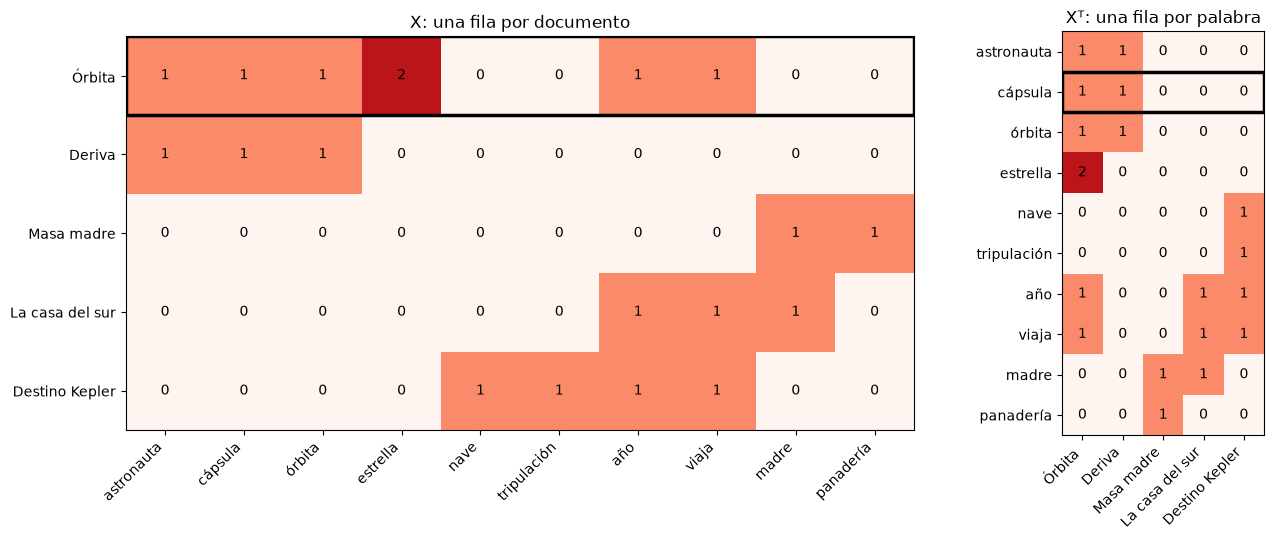

In [41]:
palabras_ej = ["astronauta", "cápsula", "órbita", "estrella", "nave", "tripulación",
               "año", "viaja", "madre", "panadería"]
columnas_ej = [bow.vocabulary_[p] for p in palabras_ej]
M = pd.DataFrame(X_bow[:, columnas_ej].toarray(), index=titulos, columns=palabras_ej)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [2, 1.1]})
for ax, T, titulo, fila in [(ejes[0], M, "X: una fila por documento", "Órbita"),
                            (ejes[1], M.T, "Xᵀ: una fila por palabra", "cápsula")]:
    ax.imshow(T, cmap="Reds", vmin=0, vmax=2.5)
    ax.set_title(titulo)
    ax.set_xticks(range(T.shape[1]), T.columns, rotation=45, ha="right")
    ax.set_yticks(range(T.shape[0]), T.index)
    for (i, j), valor in np.ndenumerate(T.values):
        ax.text(j, i, valor, ha="center", va="center")
    i = list(T.index).index(fila)   # recuadro en la fila que leemos como vector
    ax.add_patch(plt.Rectangle((-0.5, i - 0.5), T.shape[1], 1, fill=False, lw=2.5))
plt.tight_layout()

Leídas así, *cápsula*, *astronauta* y *órbita* tienen el mismo vector, (1, 1, 0, 0, 0): aparecen en las mismas dos sinopsis, y su coseno es 1. *Nave* es (0, 0, 0, 0, 1): no comparte ninguna sinopsis con *cápsula*, y su coseno es 0. Con cinco documentos, un vector de palabra tiene solo cinco coordenadas y dice poco. Con las 20.559 sinopsis de Wikipedia tiene 20.559.

Comparamos algunos pares de dos formas: con las columnas de la matriz TF-IDF (20.559 coordenadas) y con los vectores LSA de las palabras, las filas de $V_k \Sigma_k$ (100 coordenadas).

In [42]:
palabras_wiki = tfidf.get_feature_names_out()
col_tfidf = X_wiki_tfidf.T.tocsr()                    # una fila por palabra
col_lsa = svd.components_.T * svd.singular_values_    # una fila por palabra, k = 100


def similitud(M, a, b):
    i, j = tfidf.vocabulary_[a], tfidf.vocabulary_[b]
    return cosine_similarity(M[i:i + 1], M[j:j + 1])[0, 0]


pares = [("nave", "cápsula"), ("astronauta", "tripulación"), ("nave", "panadería")]
pd.DataFrame({"columnas TF-IDF": [similitud(col_tfidf, a, b) for a, b in pares],
              "LSA": [similitud(col_lsa, a, b) for a, b in pares]},
             index=[f"{a} – {b}" for a, b in pares]).round(2)

,columnas TF-IDF,LSA
nave – cápsula,0.12,0.89
astronauta – tripulación,0.06,0.71
nave – panadería,0.00,0.00


*Nave* y *cápsula* casi no comparten sinopsis: sus columnas tienen coseno 0,12. En el espacio LSA quedan en 0,89, porque aparecen junto a las mismas palabras. Por eso Destino Kepler se acercó a Órbita. *Nave* y *panadería* siguen en 0 con las dos representaciones.

Con los vectores LSA también podemos buscar las palabras más cercanas a una dada.

In [43]:
def vecinos(palabra: str, n: int = 8) -> pd.Series:
    """Las n palabras con vector LSA más parecido, entre las que aparecen en 50 sinopsis o más."""
    i = tfidf.vocabulary_[palabra]
    cosenos = pd.Series(cosine_similarity(col_lsa[i:i + 1], col_lsa)[0], index=palabras_wiki)
    return cosenos[pesos["df"] >= 50].drop(palabra, errors="ignore").nlargest(n).round(2)


vecinos("astronauta")

espacial          0.95
espaciales        0.92
planeta           0.92
órbita            0.92
nave              0.92
espacio           0.90
extraterrestre    0.90
planetas          0.90
dtype: float64

Los vecinos de *astronauta* son palabras del mismo tema: *espacial*, *órbita*, *nave*, *planeta*. Nadie le entregó al modelo una lista de significados; las relaciones salen de qué palabras aparecen en las mismas sinopsis. Vecinas no quiere decir sinónimas: están relacionadas por el tema.

Este es el modelo detrás del juego *Conecta las palabras*, y la idea que retomamos en la clase 3 con los *word embeddings*.

## 10. Un límite: el orden

Las tres representaciones parten de una bolsa de palabras. Dos oraciones con las mismas palabras en distinto orden reciben el mismo vector.

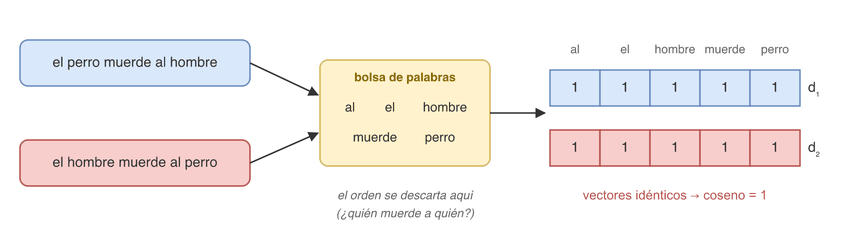

In [44]:
oraciones = ["El perro muerde al hombre.", "El hombre muerde al perro."]
X_oraciones = CountVectorizer().fit_transform(oraciones)
print("coseno:", cosine_similarity(X_oraciones)[0, 1].round(2))

coseno: 1.0


## Resumen

- En una matriz documento-término, cada fila es un documento y cada columna, una palabra. El coseno compara la dirección de dos vectores y no depende del largo del texto.
- TF-IDF baja el peso de las palabras que aparecen en muchos documentos. Cambia el orden de los resultados: con conteos gana La casa del sur; con TF-IDF, Deriva.
- Con BoW y TF-IDF dos documentos solo se parecen si comparten palabras. LSA comprime la matriz con una SVD truncada y acerca documentos que usan palabras distintas en contextos parecidos: con LSA gana Destino Kepler.
- Un vectorizador se ajusta una vez sobre el corpus (`fit`) y después representa cualquier texto (`transform`). `CountVectorizer` aprende el vocabulario; `TfidfVectorizer`, además, el idf de cada palabra; `TruncatedSVD`, la matriz $V_k$ (traspuesta, en `components_`).
- Las matrices BoW y TF-IDF son dispersas: en la de Wikipedia, el 0,09 % de las celdas es distinto de cero. La matriz LSA es densa, con 100 coordenadas por documento.
- Las columnas de la misma matriz son vectores de palabras. En la clase 3 aprenderemos esos vectores directamente: los *word embeddings*.

## Lecturas

- Jurafsky, D. y Martin, J. H. *Speech and Language Processing*, 3.ª ed. (borrador). Capítulo «Embeddings». https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P. y Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. Capítulos 6 y 18. https://nlp.stanford.edu/IR-book/
- Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K. y Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391–407.
- scikit-learn, guía de usuario, «Text feature extraction»: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- scikit-learn, guía de usuario, «Truncated singular value decomposition and latent semantic analysis»: https://scikit-learn.org/stable/modules/decomposition.html#lsa
- Boleda, G. (2026). *Distributional Semantics*. En *Open Encyclopedia of Cognitive Science*. MIT Press. https://oecs.mit.edu/pub/gbaucew9